In [1]:
import json
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core import Composition, Element

TIER1_TOXIC = ["Cd", "Hg", "Pb", "Tl", "As", "Be", "Te", "Co", "Cr", "Ni", "Sb"]
TIER2_CAUTION = ["Co", "H"]
REMOVE_RADIOACTIVE = True
REMOVE_TIER2 = True
EXTRA_EXCLUDE =[]

RADIOACTIVE = {el.symbol for el in Element if el.Z in (43, 61) or el.Z >= 84}

HERE = Path.cwd()
candidates = [HERE / "data",
              HERE,
              HERE / "nootebooks" / "data" / "data",
              HERE / "notebook" / "data"
              ]

DATA_DIR = next((p for p in candidates if (p / "BandEdge.csv").exists()), None)
assert DATA_DIR is not None, "BandEdge.csv not found. Run the BandEdge.ipynb first."

IN_PATH = DATA_DIR / "BandEdge.csv"
OUT_PATH = DATA_DIR / "Toxicity.csv"
REMOVED_PATH = DATA_DIR / "Toxicity_removed.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Input:", IN_PATH)


Input: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\BandEdge.csv


In [2]:
df = pd.read_csv(IN_PATH)
print("BandEdge.csv shape", df.shape)

def get_elements(row):
    el = row.get("elements")
    if isinstance(el, str) and el.strip():
        return [e for e in re.split(r"[-_]", el) if e]
    try:
        return [e.symbol for e in Composition(row["formula"]).elements]
    except Exception:
        return[]
assert ("elements" in df.columns) or ("formula" in df.colums), "Need an elements or formula column."
df["element_list"] = df.apply(get_elements, axis=1)
print("Rows with no element information:", int((df["element_list"].str.len() == 0).sum()))

BandEdge.csv shape (2952, 30)
Rows with no element information: 0


In [3]:
remove_set = set(TIER1_TOXIC) | set(EXTRA_EXCLUDE)
if REMOVE_RADIOACTIVE:
    remove_set |= RADIOACTIVE
if REMOVE_TIER2:
    remove_set |= set(TIER2_CAUTION)

def reasons(elements):
    out = []
    for e in elements:
        if e in TIER1_TOXIC:
            out.append(f"toxic:{e}")
        elif e in RADIOACTIVE and REMOVE_RADIOACTIVE:
            out.append(f"radioactive:{e}")
        elif e in TIER2_CAUTION and REMOVE_TIER2:
            out.append(f"caution:{e}")
        elif e in EXTRA_EXCLUDE:
            out.append(f"excludeed:{e}")
    return ";".join(out)

df["removal_reason"] = df["element_list"].apply(reasons)
df["caution_elements"] = df["element_list"].apply(lambda els: ";".join(e for e in els if e in TIER2_CAUTION))

is_removed = df["removal_reason"] != ""
tox_df = df[~is_removed].drop(columns=["element_list", "removal_reason"]).reset_index(drop=True)
removed_df = df[is_removed].drop(columns=["element_list"]).reset_index(drop=True)



print("Screening funnel")
print(f"    BandEdge.csv                                        : {len(df):,}")
print(f"    removed in total                                    :{len(removed_df):,}")
print(f"    kept (Toxicity.csv)                                 :  {len(tox_df):,} ({len(tox_df) / len(df):.1%})")


per_element = Counter(e for els in df["element_list"] for e in set(els) if e in remove_set)
print()
print("Materials containing each removed element:")
print(pd.Series(per_element).sort_values(ascending=False).to_string())

    


Screening funnel
    BandEdge.csv                                        : 2,952
    removed in total                                    :841
    kept (Toxicity.csv)                                 :  2,111 (71.5%)

Materials containing each removed element:
Co    105
Tl     98
Cd     95
H      91
Cr     89
Ni     87
Pb     80
Hg     48
Sb     44
U      43
Te     30
As     30
Th     15
Tc     12
Be     11
Pm      7
Pa      5
Ac      3
Np      2
Pu      1


Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Toxicity.csv
Files existe: True
{
  "saved_at": "2026-11-03T21:22:50",
  "input_file": "BandEdge.csv",
  "output_file": "Toxicity.csv",
  "tier1_toxic": [
    "Cd",
    "Hg",
    "Pb",
    "Tl",
    "As",
    "Be",
    "Te",
    "Co",
    "Cr",
    "Ni",
    "Sb"
  ],
  "tier2_caution": [
    "Co",
    "H"
  ],
  "tier2_removed": true,
  "radioactive_removed": true,
  "rows_in": 2952,
  "removed_toxic": 676,
  "removed_radioactive": 88,
  "row_kept": 2111,
  "row_removed": 841,
  "kept_with_caution_element": 0
}


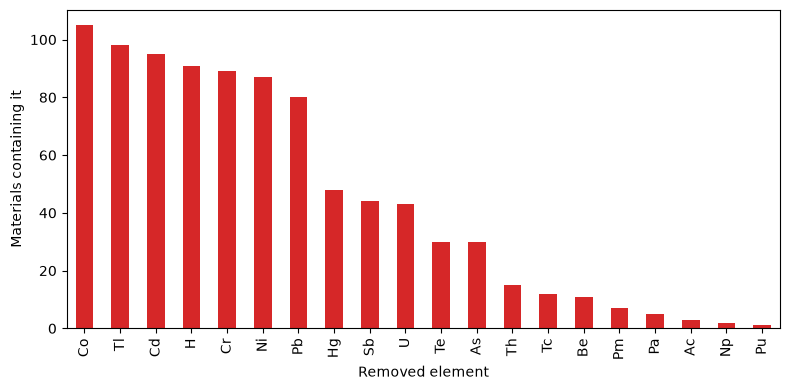

In [5]:
tox_df.to_csv(OUT_PATH, index=False)
removed_df.to_csv(REMOVED_PATH, index=False)

n_toxic = int(removed_df["removal_reason"].str.contains("toxic:").sum())
n_radio = int(removed_df["removal_reason"].str.contains("radioactive:").sum())

summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": IN_PATH.name,
    "output_file": OUT_PATH.name,
    "tier1_toxic": TIER1_TOXIC,
    "tier2_caution": TIER2_CAUTION,
    "tier2_removed": REMOVE_TIER2,
    "radioactive_removed": REMOVE_RADIOACTIVE,
    "rows_in": int(len(df)),
    "removed_toxic": n_toxic,
    "removed_radioactive": n_radio,
    "row_kept": int(len(tox_df)),
    "row_removed": int(len(removed_df)),
    "kept_with_caution_element": int((tox_df["caution_elements"] != "").sum()),
   
}
(DATA_DIR / f"{OUT_PATH.stem}_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_PATH)
print("Files existe:", OUT_PATH.exists())
print(json.dumps(summary, indent=2))


top = pd.Series(per_element).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 4))
top.plot.bar(ax=ax, color="tab:red")
ax.set_xlabel("Removed element"); ax.set_ylabel("Materials containing it");
plt.tight_layout()
plt.savefig(FIG_DIR / "toxicity_screening.png", dpi=200)
plt.show()



